In [2]:
import math
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import StatePreparation, DraperQFTAdder, QFT

In [3]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import StatePreparation, DraperQFTAdder, QFT
from qiskit_aer import AerSimulator


# ==============================================================================
# MODULE 1: Fixed-Point Two's Complement Helper
# ==============================================================================
class FixedPointHelper:
    """Utility class for Two's Complement encoding and conversion."""
    def __init__(self, num_bits: int = 5, frac_bits: int = 3):
        self.num_bits = num_bits
        self.frac_bits = frac_bits
        self.int_bits = num_bits - frac_bits
        self.scale = 2 ** frac_bits
        self.min_val = - (2 ** (self.int_bits - 1))
        self.max_val = (2 ** (self.int_bits - 1)) - (1 / self.scale)

    def float_to_bin(self, val: float) -> str:
        val_clamped = max(min(val, self.max_val), self.min_val)
        int_rep = int(round(val_clamped * self.scale))
        if int_rep < 0:
            int_rep = (1 << self.num_bits) + int_rep
        return format(int_rep, f'0{self.num_bits}b')

    def bin_to_float(self, bin_str: str) -> float:
        int_rep = int(bin_str, 2)
        if int_rep & (1 << (self.num_bits - 1)):
            int_rep -= (1 << self.num_bits)
        return int_rep / self.scale


# ==============================================================================
# MODULE 2: QFT Multiplier with Corrected Phase Formula
# ==============================================================================
def build_signed_qft_multiplier(num_bits: int = 5, frac_bits: int = 3) -> QuantumCircuit:
    """Computes out = y * v in fixed-point QFT domain for Two's Complement inputs."""
    reg_y = QuantumRegister(num_bits, name="y")
    reg_v = QuantumRegister(num_bits, name="v")
    reg_out = QuantumRegister(num_bits, name="out")
    qc = QuantumCircuit(reg_y, reg_v, reg_out, name="Signed_QFT_Multiplier")

    qft_gate = QFT(num_qubits=num_bits, do_swaps=False).to_gate()
    iqft_gate = qft_gate.inverse()

    qc.append(qft_gate, reg_out)

    for i in range(num_bits):
        weight_i = (2 ** i) if i < num_bits - 1 else -(2 ** (num_bits - 1))
        for j in range(num_bits):
            weight_j = (2 ** j) if j < num_bits - 1 else -(2 ** (num_bits - 1))
            prod_weight = weight_i * weight_j

            for k in range(num_bits):
                # CORRECTED PHASE FORMULA: 2^(num_bits + frac_bits - k)
                angle = 2 * np.pi * (prod_weight / (2 ** (k + frac_bits + 1)))
                if angle % (2 * np.pi) != 0:
                    qc.mcp(angle, [reg_y[i], reg_v[j]], reg_out[k])

    qc.append(iqft_gate, reg_out)
    return qc


def build_gaussian_rv_circuit(num_bits: int = 5, frac_bits: int = 3, mean: float = 0.0, std: float = 1.0) -> QuantumCircuit:
    helper = FixedPointHelper(num_bits, frac_bits)
    num_states = 2 ** num_bits

    grid_vals = [helper.bin_to_float(format(i, f'0{num_bits}b')) for i in range(num_states)]
    probabilities = np.exp(-0.5 * ((np.array(grid_vals) - mean) / std) ** 2)
    probabilities /= np.sum(probabilities)
    amplitudes = np.sqrt(probabilities)

    reg_w = QuantumRegister(num_bits, name="W_gauss")
    qc = QuantumCircuit(reg_w, name="Gaussian_RV")
    qc.append(StatePreparation(amplitudes), reg_w)
    return qc


def build_scalar_multiplier(num_bits: int = 5, scalar: float = 0.5) -> QuantumCircuit:
    """Right-shift multiplier by 0.5 (T = 0.5) for Two's Complement values."""
    reg_in = QuantumRegister(num_bits, name="in")
    reg_out = QuantumRegister(num_bits, name="out_mult")
    qc = QuantumCircuit(reg_in, reg_out, name=f"Mult_{scalar}")

    if scalar == 0.5:
        # Shift bits right by 1
        for i in range(1, num_bits):
            qc.cx(reg_in[i], reg_out[i - 1])
        # Sign extension for Two's Complement
        qc.cx(reg_in[num_bits - 1], reg_out[num_bits - 1])
    return qc


# ==============================================================================
# MODULE 3: Integrated Compact Circuit Assembly
# ==============================================================================
def build_u_2_1_compact_circuit(
    T: float = 0.5, x_val: float = 0.5, num_bits: int = 5, frac_bits: int = 3
) -> QuantumCircuit:
    helper = FixedPointHelper(num_bits, frac_bits)

    reg_w_s1 = QuantumRegister(num_bits, name="w_s1")
    reg_y_s1 = QuantumRegister(num_bits, name="y_s1")
    reg_v1 = QuantumRegister(num_bits, name="v1")
    reg_out_f = QuantumRegister(num_bits, name="out_f")
    reg_scaled_f = QuantumRegister(num_bits, name="scaled_f")
    reg_acc = QuantumRegister(num_bits, name="acc")

    cr = ClassicalRegister(num_bits, name="meas")

    qc = QuantumCircuit(
        reg_w_s1, reg_y_s1, reg_v1, reg_out_f, reg_scaled_f, reg_acc,
        cr, name="U_2_1_Compact"
    )

    # 1. Preset accumulator reg_acc directly to g_d(x + W_T) = 1.0
    bin_one = helper.float_to_bin(1.0)
    for i, bit in enumerate(reversed(bin_one)):
        if bit == "1":
            qc.x(reg_acc[i])

    # 2. Preset v1 = g_d(...) = 1.0
    for i, bit in enumerate(reversed(bin_one)):
        if bit == "1":
            qc.x(reg_v1[i])

    # 3. Encode x into reg_y_s1 and sample W_{R_0^1}^1
    bin_x = helper.float_to_bin(x_val)
    for i, bit in enumerate(reversed(bin_x)):
        if bit == "1":
            qc.x(reg_y_s1[i])

    gauss_gate = build_gaussian_rv_circuit(num_bits, frac_bits, std=np.sqrt(T / 2.0)).to_gate()
    qc.append(gauss_gate, reg_w_s1)

    # 4. Trajectory reg_y_s1 = x + W_{R_0^1}^1
    adder_gate = DraperQFTAdder(num_bits).to_gate()
    qc.append(adder_gate, list(reg_w_s1) + list(reg_y_s1))

    # 5. Evaluate f_d(y_s1, v1) = y_s1 * v1
    mult_gate = build_signed_qft_multiplier(num_bits, frac_bits).to_gate()
    qc.append(mult_gate, list(reg_y_s1) + list(reg_v1) + list(reg_out_f))

    # 6. Scale by T = 0.5 and accumulate into reg_acc
    mult_T = build_scalar_multiplier(num_bits, scalar=T).to_gate()
    qc.append(mult_T, list(reg_out_f) + list(reg_scaled_f))
    qc.append(adder_gate, list(reg_scaled_f) + list(reg_acc))

    qc.measure(reg_acc, cr)
    return qc


In [4]:
T_val = 0.5
x_val = 0.5
num_bits = 6
frac_bits = 3

    # Instantiate unrolled quantum circuit
u_2_1_circuit = build_u_2_1_compact_circuit(T=T_val, x_val=x_val, num_bits=num_bits, frac_bits=frac_bits)

print(f"Successfully constructed U^1_{{2,1}}(0, {x_val}) Quantum Circuit.")
print(f"Total Qubits: {u_2_1_circuit.num_qubits}")
print(f"Circuit Depth: {u_2_1_circuit.depth()}")

Successfully constructed U^1_{2,1}(0, 0.5) Quantum Circuit.
Total Qubits: 36
Circuit Depth: 6


/var/folders/9w/d8g6spn108bgqts_cc8230000000gn/T/ipykernel_45708/2297551007.py:44: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_gate = QFT(num_qubits=num_bits, do_swaps=False).to_gate()


In [6]:
from qiskit import transpile
from qiskit_aer import AerSimulator

# 2. Use Matrix Product State (MPS) simulator to bypass the 24-qubit RAM barrier
sim_mps = AerSimulator(method="matrix_product_state")

# 3. Transpile and execute
qc_transpiled = transpile(u_2_1_circuit, sim_mps)
result = sim_mps.run(qc_transpiled, shots=1000).result()
counts = result.get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'000110': 35, '001100': 94, '000100': 3, '001011': 133, '000101': 16, '001111': 4, '001101': 41, '001110': 25, '001000': 163, '000011': 2, '000111': 88, '001001': 190, '001010': 206}


In [14]:
fphelp = FixedPointHelper(num_bits, frac_bits)
#fphelp.bin_to_float('00110')

prob_profile = []
prob_profile_dict = {}
ev = 0

for k,v in counts.items():
    prob_profile.append((fphelp.bin_to_float(k), v))
    prob_profile_dict[fphelp.bin_to_float(k)] = v
    ev += fphelp.bin_to_float(k) * v

prob_profile.sort()
ev = ev/1000

print(prob_profile)
print(ev)

prob_profiles_val, prob_profiles_count = [], []
for val in prob_profile:
    prob_profiles_val.append(str(val[0]))
    prob_profiles_count.append(val[1])

[(0.375, 2), (0.5, 3), (0.625, 16), (0.75, 35), (0.875, 88), (1.0, 163), (1.125, 190), (1.25, 206), (1.375, 133), (1.5, 94), (1.625, 41), (1.75, 25), (1.875, 4)]
1.1915


In [8]:
from mlp import MLPSolver

d = 1
T = 0.5
n_level = 2
M_branch = 1
num_trials = 1000

def g_n(x: np.ndarray) -> float:
    return 1

def f_n(t: float, x: np.ndarray, v: float) -> float:
    return v*x#np.sin(v + x) 

solver = MLPSolver(f=f_n, g=g_n, T=T)
res = solver.evaluate_trials(0, [0.5], n=n_level, M=M_branch, num_trials=num_trials)
print(res['trials'])
print(res['mean'])

trials = []
for val in res['trials']:
    trials.append(val[0])
disc_trials = []
for val in res['trials']:
    disc_trials.append(math.floor(val[0] / 0.125)*0.125)
print(disc_trials)

[array([1.0131832]), array([1.28273694]), array([1.21660832]), array([1.14761403]), array([1.68942729]), array([1.47666858]), array([0.83746282]), array([1.44598052]), array([1.01763509]), array([1.47894085]), array([0.80857629]), array([1.7486996]), array([1.13707319]), array([1.38030058]), array([0.8469394]), array([0.93189442]), array([1.42775345]), array([1.3836415]), array([1.27674553]), array([0.26766546]), array([1.42347717]), array([1.38435899]), array([1.17107947]), array([1.47787527]), array([1.54599522]), array([1.33635584]), array([0.59964295]), array([1.18759018]), array([1.27261559]), array([1.11015521]), array([1.3438646]), array([1.13248658]), array([0.74603866]), array([0.87785613]), array([1.21960015]), array([1.44207146]), array([1.62794705]), array([1.25334162]), array([1.33199983]), array([0.7649051]), array([0.76162144]), array([1.32405048]), array([1.02744838]), array([1.30731062]), array([1.16936569]), array([1.05498916]), array([1.17996941]), array([1.23880167]

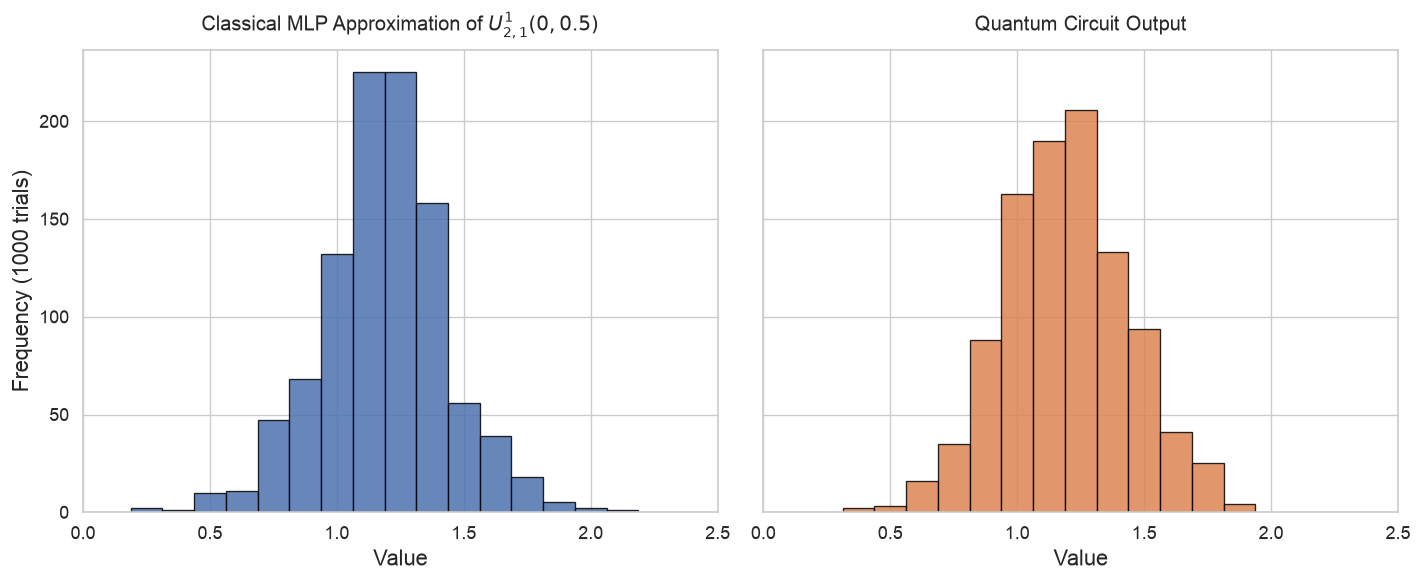

In [16]:
import seaborn as sns
import numpy as np
from collections import Counter

q_counts = prob_profile_dict
c_trials = disc_trials

c_counts = Counter(c_trials)

q_x = sorted(list(q_counts.keys()))
q_y = [q_counts[k] for k in q_x]

c_x = sorted(list(c_counts.keys()))
c_y = [c_counts[k] for k in c_x]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, dpi=120)

bin_width = 0.125

axes[0].bar(c_x, c_y, width=bin_width, color='#4C72B0', edgecolor='black', alpha=0.85)
axes[0].set_title(r"Classical MLP Approximation of $U^1_{2,1}(0, 0.5)$", fontsize=12, pad=12)
axes[0].set_xlabel("Value", fontsize=13)
axes[0].set_ylabel("Frequency (1000 trials)", fontsize=13)
axes[0].set_xlim(0, 2.5)

axes[1].bar(q_x, q_y, width=bin_width, color='#DD8452', edgecolor='black', alpha=0.85)
axes[1].set_title(r"Quantum Circuit Output", fontsize=12, pad=12)
axes[1].set_xlabel("Value", fontsize=13)
axes[1].set_xlim(0, 2.5)

plt.tight_layout()
plt.show()

